# Simulazione: rumore standard + BAND NOISE LOFAR, 50 componenti

Notebook unico per tutte le ampiezze di band noise: si cambia a mano **solo la cella dei parametri** qui sotto
e si esegue tutto.

| componente | parametri |
|---|---|
| red_noise | gamma = 0.1324, log10_A = -13.213 (valori standard) |
| dm_gp (alpha = 2) | gamma = 6.471, log10_A = -15.723 (valori standard) |
| sv_gp (**alpha = 4.4**) | gamma = 1.326, log10_A = -15.888 (valori standard) |
| **band_noise** (LOFAR, **50 componenti**) | **gamma = 3.0, log10_A = `log10_A_bn`** |

Simulazioni previste:

| `log10_A_bn` | `nome_sim` | cartella |
|---|---|---|
| -30.0 (spento) | `OFF` | `sim_data_noise_bn_OFF_sv44_50componenti/` |
| -13.0 | `A130` | `sim_data_noise_bn_A130_sv44_50componenti/` |
| -12.5 | `A125` | `sim_data_noise_bn_A125_sv44_50componenti/` |
| -12.0 | `A120` | `sim_data_noise_bn_A120_sv44_50componenti/` |

Tutte usano lo stesso modello (4 GP, 50 componenti di band noise) e lo stesso seed `key(1)`: red noise, DM e
scattering hanno quindi **la stessa identica realizzazione** in tutte, e cambia solo l ampiezza del band noise.
La `OFF` (band noise a -30, cioe spento) e la baseline: le differenze fra le analisi su `OFF` e su `A1xx` sono
dovute solo al band noise. **Generare per prima la `OFF`**: l ultima cella usa la `OFF` per verificare che la
realizzazione sia davvero la stessa.

50 componenti: a -12 con gamma = 3 il band noise emerge sopra il rumore bianco LOFAR solo fino alla
componente ~15-20, quindi 50 coprono tutto l intervallo utile.

In [31]:
import numpy as np
import os, glob, json
import pickle

import sys

# this is the path to the discovery folder
sys.path.insert(0, "./")
import discovery_new as ds

import matplotlib.pyplot as plt
import scipy
import jax.numpy as jnp

from scipy.stats import uniform
import jax

import copy

## Parametri della simulazione (DA CAMBIARE A MANO)

In [32]:
log10_A_bn = -12.0      # -30.0 (OFF), -13.0, -12.5, -12.0
nome_sim   = 'A120'     # 'OFF', 'A130', 'A125', 'A120'

dirpath = f'sim_data_noise_bn_{nome_sim}_sv44_50componenti/'
print('simulo band noise a log10_A =', log10_A_bn, '->', dirpath)

simulo band noise a log10_A = -12.0 -> sim_data_noise_bn_A120_sv44_50componenti/


In [33]:
# this are the data we want to replicate
path = './dati/DR2low_feathers/'
s_dsfiles = np.sort(os.listdir(path))
psr = [ds.pulsar.Pulsar.read_feather(path + f'{psrfile}') for psrfile in s_dsfiles][9]
print('pulsar :', psr.name)
print('N_TOA  :', len(psr.toas))

pulsar : J1640+2224
N_TOA  : 6777


In [34]:
# quante ToA prende la selezione LOFAR, e a che frequenze
sel = ds.lofar_backends(psr)
mask_lofar = np.any(np.vstack([np.asarray(m, dtype=bool) for m in sel.values()]), axis=0)
print('backend selezionati :', sorted(sel.keys()))
print(f'ToA nella selezione : {mask_lofar.sum()} su {len(psr.toas)}  ({100*mask_lofar.mean():.1f}%)')
print(f'frequenze           : {psr.freqs[mask_lofar].min():.1f} - {psr.freqs[mask_lofar].max():.1f} MHz')
print('componenti band noise: 50')

backend selezionati : ['DE601.150', 'DE602.150', 'DE603.150', 'DE604.150', 'DE605.150', 'DE609.150', 'LOFAR.150']
ToA nella selezione : 5232 su 6777  (77.2%)
frequenze           : 121.3 - 185.5 MHz
componenti band noise: 50


In [35]:
###### Let's put in the model the components we want to simulate (comment a line if you don't want to inject that process)
## scattering con alpha = 4.4 + BAND NOISE sui backend LOFAR

# data
model = [psr.residuals]
# timing model
model += [ds.makegp_timing(psr, svd=True, variance=1e-40)]
# white noise parameters
model += [ds.makenoise_measurement(psr, psr.noisedict, tnequad = True, ecorr=True)]
# red noise paramters
model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_red_components'], T=ds.getspan(psr), name='red_noise' ))
# DM variation parameters
model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_dm_components'], T=ds.getspan(psr), name='dm_gp', fourierbasis=ds.make_dmfourierbasis(alpha = 2.0, tndm = False)))
# scattering noise parameters  --> alpha = 4.4
model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_chrom_components'], T=ds.getspan(psr), name='sv_gp', fourierbasis=ds.make_dmfourierbasis(alpha = 4.4, tndm = False)))
# BAND NOISE sui backend LOFAR, 50 componenti
model.append(ds.makegp_fourier_select(psr, ds.powerlaw, components=50, T=ds.getspan(psr),
                                      name='band_noise', selection=ds.lofar_backends))

In [36]:
gml = ds.PulsarLikelihood(model)
logL = ds.PulsarLikelihood(model).logL

In [37]:
logL.params   # attesi 8 parametri: i 6 standard + band_noise_gamma e band_noise_log10_A

['J1640+2224_band_noise_gamma',
 'J1640+2224_band_noise_log10_A',
 'J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [38]:
# valori standard, senza GWB, + band noise a log10_A = log10_A_bn
truths = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
    # band noise sui backend LOFAR
    'J1640+2224_band_noise_gamma': 3.0,
    'J1640+2224_band_noise_log10_A': log10_A_bn,
}

assert set(logL.params) == set(truths.keys()), \
    f"Mancanti: {set(logL.params) - set(truths.keys())}\nIn eccesso: {set(truths.keys()) - set(logL.params)}"
print('OK: parametri e truths coincidono')

OK: parametri e truths coincidono


In [39]:
# sample from the likelihood! jax.random.key(42) is the seed of the random extraction, you can change it to have a different realisation od the data simulated
_, residuals = gml.sample(jax.random.key(1), truths)

In [40]:
# make a copy of the pulsar object and overwite the residuals with the simulated ones
sim_psr = copy.deepcopy(psr)
sim_psr.residuals = np.array(residuals)

In [41]:
# dirpath e definito nella cella dei parametri
if not os.path.exists(dirpath):
    os.makedirs(dirpath)
ds.pulsar.Pulsar.save_feather(sim_psr, dirpath + psr.name, noisedict=psr.noisedict)
print('salvato in', os.path.abspath(dirpath))
print(os.listdir(dirpath))

salvato in /Users/lorenzocaivano/Desktop/Anno3Fisica/Tesi/sim_data_noise_bn_A120_sv44_50componenti
['J1640+2224']


In [42]:
# controlli: rileggo il feather appena scritto
check = ds.pulsar.Pulsar.read_feather(dirpath + psr.name)
print('N_TOA              :', len(check.toas))
print('std residui salvati:', np.std(check.residuals))
print('std residui reali  :', np.std(psr.residuals))

# il band noise vive solo in banda LOFAR: lo std dei residui simulati deve essere
# piu grande di quello dei reali soprattutto nella banda selezionata
for etichetta, m in [('LOFAR (121-185 MHz)', mask_lofar), ('resto (>1 GHz)', ~mask_lofar)]:
    print(f'{etichetta:22s}  simulati {np.std(check.residuals[m]):.3e}   reali {np.std(psr.residuals[m]):.3e}')

N_TOA              : 6777
std residui salvati: 7.180077033916629e-05
std residui reali  : 4.9727599776051104e-05
LOFAR (121-185 MHz)     simulati 8.077e-05   reali 5.644e-05
resto (>1 GHz)          simulati 8.338e-06   reali 7.645e-06


### Residui simulati, colorati per frequenza radio

Se il band noise e stato iniettato correttamente, l eccesso di scatter si concentra nei punti di colore scuro (basse frequenze, LOFAR) e non in quelli chiari (L-band).

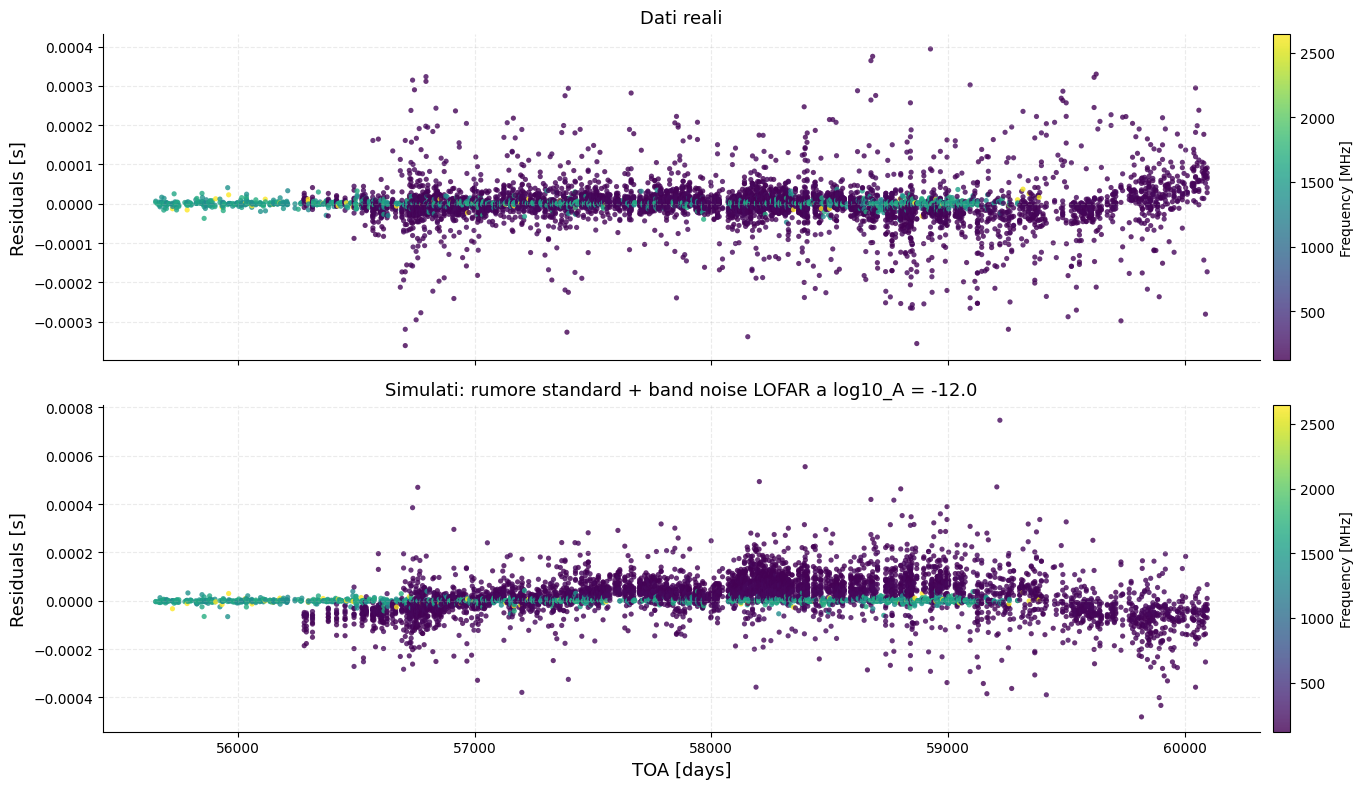

In [43]:
fig, ax = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

for a, (res, titolo) in zip(ax, [(psr.residuals, 'Dati reali'),
                                 (sim_psr.residuals, f'Simulati: rumore standard + band noise LOFAR a log10_A = {log10_A_bn}')]):
    sc = a.scatter(psr.toas / 86400, res, c=psr.freqs, s=14, alpha=0.8, cmap='viridis', edgecolors='none')
    a.set_ylabel('Residuals [s]', fontsize=13)
    a.set_title(titolo, fontsize=13, pad=8)
    a.grid(alpha=0.25, linestyle='--')
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    cbar = fig.colorbar(sc, ax=a, pad=0.01)
    cbar.set_label('Frequency [MHz]', fontsize=10)

ax[1].set_xlabel('TOA [days]', fontsize=13)
fig.tight_layout()
fig.savefig(f'residui_sim_bn_{nome_sim}_sv44_50comp.png', dpi=150, bbox_inches='tight')

nel pannello di destra: un band noise puro darebbe un andamento PIATTO,
lo scattering alpha=4.4 da solo darebbe un fattore 6.5 fra 185 e 121 MHz.
qui vedi la somma dei due.


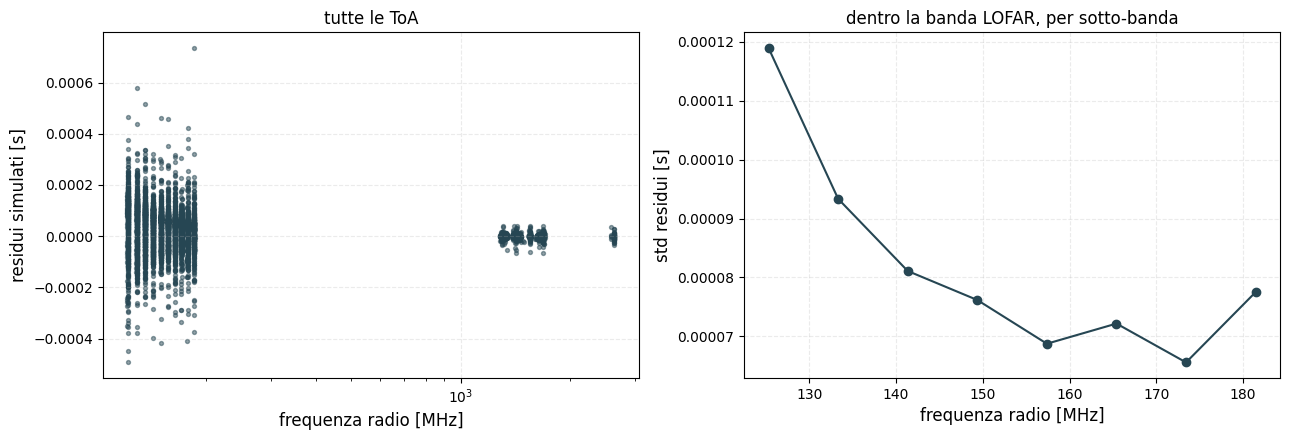

In [29]:
# scatter dei residui in funzione della frequenza radio: il band noise e piatto entro la
# banda LOFAR, mentre lo scattering (alpha = 4.4) cresce come nu^-4.4 verso il basso
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].scatter(psr.freqs, sim_psr.residuals, s=8, alpha=0.5, color='#264653')
ax[0].set_xscale('log'); ax[0].set_xlabel('frequenza radio [MHz]', fontsize=12)
ax[0].set_ylabel('residui simulati [s]', fontsize=12)
ax[0].set_title('tutte le ToA', fontsize=12)
ax[0].grid(alpha=0.25, linestyle='--')

# std dei residui in bin di frequenza, solo dentro la banda LOFAR
fl = psr.freqs[mask_lofar]; rl = sim_psr.residuals[mask_lofar]
edges = np.linspace(fl.min(), fl.max(), 9)
centri, stds = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    k = (fl >= lo) & (fl < hi)
    if k.sum() > 10:
        centri.append(0.5 * (lo + hi)); stds.append(np.std(rl[k]))
ax[1].plot(centri, stds, 'o-', color='#264653')
ax[1].set_xlabel('frequenza radio [MHz]', fontsize=12)
ax[1].set_ylabel('std residui [s]', fontsize=12)
ax[1].set_title('dentro la banda LOFAR, per sotto-banda', fontsize=12)
ax[1].grid(alpha=0.25, linestyle='--')

fig.tight_layout()
fig.savefig(f'residui_sim_bn_{nome_sim}_sv44_50comp_vs_freq.png', dpi=150, bbox_inches='tight')

print('nel pannello di destra: un band noise puro darebbe un andamento PIATTO,')
print('lo scattering alpha=4.4 da solo darebbe un fattore 6.5 fra 185 e 121 MHz.')
print('qui vedi la somma dei due.')

### Controllo: stessa realizzazione della baseline OFF

Solo per le simulazioni `A1xx`, dopo aver generato la `OFF`.

La differenza fra i residui di questa simulazione e quelli della `OFF` deve essere **non nulla solo sulle
ToA LOFAR** e zero a precisione di macchina su tutte le altre: e la verifica diretta che il band noise sia
confinato in banda e che le due simulazioni condividano la stessa realizzazione degli altri processi.

In [44]:
off_path = 'sim_data_noise_bn_OFF_sv44_50componenti/' + psr.name

if nome_sim == 'OFF':
    print('questa e la baseline OFF: niente da confrontare')
elif not os.path.exists(off_path):
    print('baseline appaiata non ancora generata, confronto saltato:', off_path)
    print("per generarla: log10_A_bn = -30.0 e nome_sim = 'OFF' nella cella dei parametri, poi eseguire tutto")
else:
    off = ds.pulsar.Pulsar.read_feather(off_path)
    d = sim_psr.residuals - off.residuals

    print(f'differenza sulle ToA LOFAR    : std = {np.std(d[mask_lofar]):.3e} s   max|d| = {np.max(np.abs(d[mask_lofar])):.3e}')
    print(f'differenza sulle altre ToA    : std = {np.std(d[~mask_lofar]):.3e} s   max|d| = {np.max(np.abs(d[~mask_lofar])):.3e}')
    print()
    if np.max(np.abs(d[~mask_lofar])) < 1e-15:
        print('OK: fuori dalla banda LOFAR la differenza e zero a precisione di macchina.')
        print('    Le due simulazioni condividono la stessa realizzazione di red noise, DM e scattering,')
        print('    e differiscono SOLO per il band noise.')
    else:
        print('ATTENZIONE: differenza non nulla fuori dalla banda LOFAR.')
        print('    Le due simulazioni NON condividono la realizzazione: il confronto fra le due')
        print('    mescola l effetto del band noise con il rumore di realizzazione.')

differenza sulle ToA LOFAR    : std = 2.344e-05 s   max|d| = 4.476e-05
differenza sulle altre ToA    : std = 0.000e+00 s   max|d| = 0.000e+00

OK: fuori dalla banda LOFAR la differenza e zero a precisione di macchina.
    Le due simulazioni condividono la stessa realizzazione di red noise, DM e scattering,
    e differiscono SOLO per il band noise.
